In [ ]:
# Day 1 - Bank Customer Churn Analysis
# Step 1: Import the required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set display preferences
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 20)

# Set chart style
sns.set_style('whitegrid')

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# DAY 1 - BANK CUSTOMER CHURN ANALYSIS
# STEP 2 - LOAD THE DATASET

import pandas as pd
import glob
import os

# Find uploaded CSV files
csv_files = glob.glob('/content/*.csv')

print("CSV files found:", csv_files)

# Automatically select the uploaded dataset
file_path = csv_files[0]

# Load dataset
df = pd.read_csv(file_path)

print("\nDataset loaded successfully!")
print("File name:", os.path.basename(file_path))
print("Dataset shape:", df.shape)

CSV files found: ['/content/European_Bank (4) -csv file.csv']

Dataset loaded successfully!
File name: European_Bank (4) -csv file.csv
Dataset shape: (10000, 14)


In [ ]:
# STEP 3 - INITIAL DATA INSPECTION

# Display first 5 rows
print("FIRST 5 ROWS OF THE DATASET")
display(df.head())

# Display column names
print("\nCOLUMN NAMES")
print(df.columns.tolist())

# Display dataset information
print("\nDATASET INFORMATION")
df.info()

# Display statistical summary
print("\nSTATISTICAL SUMMARY")
display(df.describe())

FIRST 5 ROWS OF THE DATASET


,Year,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,2025,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2025,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,2025,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,2025,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,2025,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0



COLUMN NAMES
['Year', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Year             10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null

,Year,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.0,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,2025.0,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,0.0,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,2025.0,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2025.0,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,2025.0,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,2025.0,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,2025.0,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [ ]:
# STEP 4 - DATA QUALITY CHECK

# 1. Check missing values
print("MISSING VALUES IN EACH COLUMN")
display(df.isnull().sum())

# 2. Check total missing values
print("\nTOTAL MISSING VALUES:", df.isnull().sum().sum())

# 3. Check duplicate rows
print("\nTOTAL DUPLICATE ROWS:", df.duplicated().sum())

# 4. Check duplicate customer IDs
print("\nDUPLICATE CUSTOMER IDs:", df['CustomerId'].duplicated().sum())

# 5. Check dataset size
print("\nTOTAL ROWS:", df.shape[0])
print("TOTAL COLUMNS:", df.shape[1])

MISSING VALUES IN EACH COLUMN


,0
Year,0
CustomerId,0
Surname,0
CreditScore,0
Geography,0
Gender,0
Age,0
Tenure,0
Balance,0
NumOfProducts,0



TOTAL MISSING VALUES: 0

TOTAL DUPLICATE ROWS: 0

DUPLICATE CUSTOMER IDs: 0

TOTAL ROWS: 10000
TOTAL COLUMNS: 14


CUSTOMER CHURN COUNTS:


,count
Exited,
0,7963
1,2037



CUSTOMER CHURN PERCENTAGES:


,proportion
Exited,
0,79.63
1,20.37


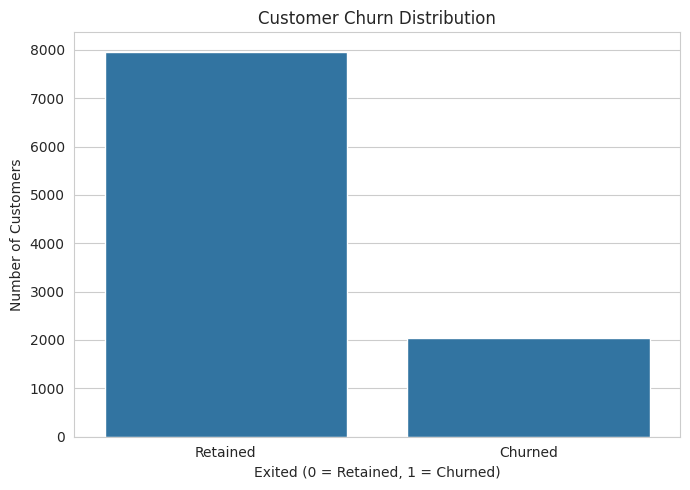

In [ ]:
# STEP 5 - CUSTOMER CHURN DISTRIBUTION

# Count customers who stayed and exited
churn_counts = df['Exited'].value_counts()

print("CUSTOMER CHURN COUNTS:")
display(churn_counts)

# Calculate percentages
churn_percentages = df['Exited'].value_counts(normalize=True) * 100

print("\nCUSTOMER CHURN PERCENTAGES:")
display(churn_percentages.round(2))

# Visualize churn distribution
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x='Exited')

plt.title('Customer Churn Distribution')
plt.xlabel('Exited (0 = Retained, 1 = Churned)')
plt.ylabel('Number of Customers')
plt.xticks([0, 1], ['Retained', 'Churned'])
plt.tight_layout()
plt.show()

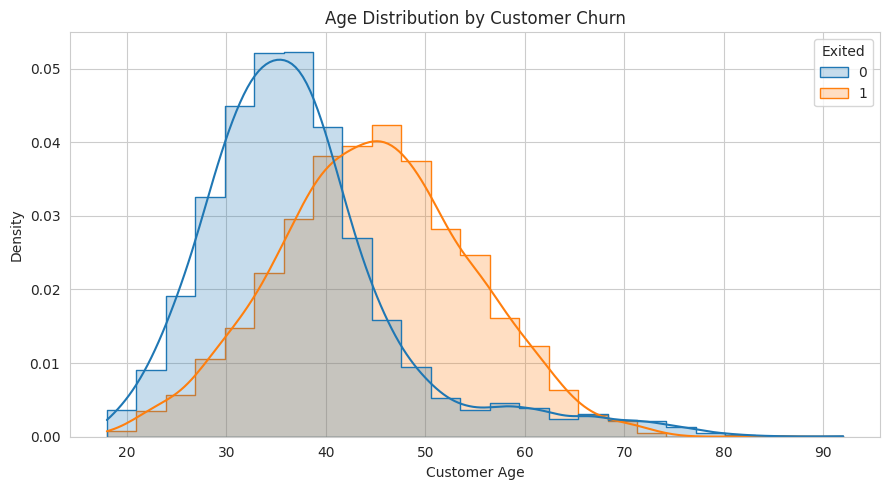

AVERAGE AGE BY CHURN STATUS:


,Age
Exited,
0,37.408389
1,44.837997



Retained customers (0) average age: 37.41
Churned customers (1) average age: 44.84


In [ ]:
# STEP 6 - CHURN ANALYSIS BY AGE

# Compare age distributions of retained and churned customers
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x='Age',
    hue='Exited',
    bins=25,
    kde=True,
    element='step',
    stat='density',
    common_norm=False
)

plt.title('Age Distribution by Customer Churn')
plt.xlabel('Customer Age')
plt.ylabel('Density')
plt.tight_layout()
plt.show()

# Calculate average age by churn status
age_summary = df.groupby('Exited')['Age'].mean()

print("AVERAGE AGE BY CHURN STATUS:")
display(age_summary)

print("\nRetained customers (0) average age:", round(age_summary[0], 2))
print("Churned customers (1) average age:", round(age_summary[1], 2))

CHURN RATE BY GEOGRAPHY (%)


,Exited
Geography,
France,16.15
Germany,32.44
Spain,16.67


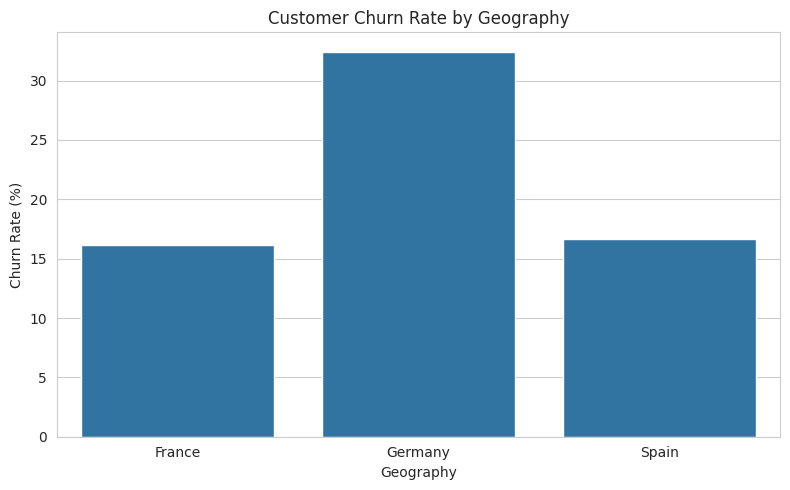


CHURN RATE BY GENDER (%)


,Exited
Gender,
Female,25.07
Male,16.46


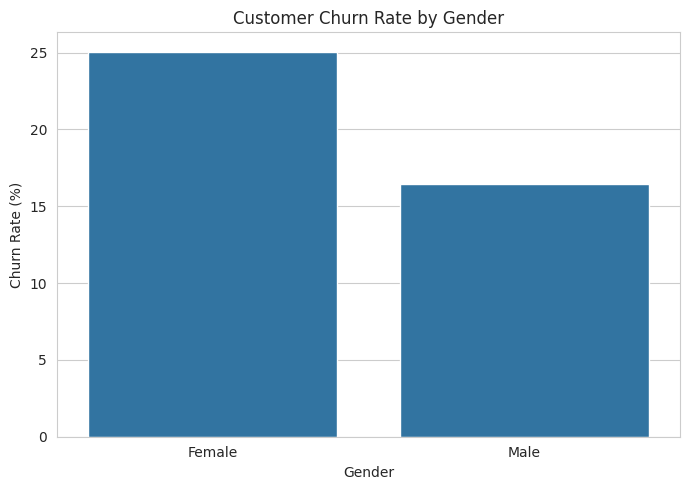

In [ ]:
# STEP 7 - CHURN BY GEOGRAPHY AND GENDER

# Calculate churn rate by Geography
geo_churn = df.groupby('Geography')['Exited'].mean() * 100

print("CHURN RATE BY GEOGRAPHY (%)")
display(geo_churn.round(2))

# Visualize Geography
plt.figure(figsize=(8, 5))
sns.barplot(x=geo_churn.index, y=geo_churn.values)

plt.title('Customer Churn Rate by Geography')
plt.xlabel('Geography')
plt.ylabel('Churn Rate (%)')
plt.tight_layout()
plt.show()

# Calculate churn rate by Gender
gender_churn = df.groupby('Gender')['Exited'].mean() * 100

print("\nCHURN RATE BY GENDER (%)")
display(gender_churn.round(2))

# Visualize Gender
plt.figure(figsize=(7, 5))
sns.barplot(x=gender_churn.index, y=gender_churn.values)

plt.title('Customer Churn Rate by Gender')
plt.xlabel('Gender')
plt.ylabel('Churn Rate (%)')
plt.tight_layout()
plt.show()

CHURN RATE BY TENURE (%)


,Exited
Tenure,
0,23.00
1,22.42
2,19.18
3,21.11
4,20.53
5,20.65
6,20.27
7,17.22
8,19.22


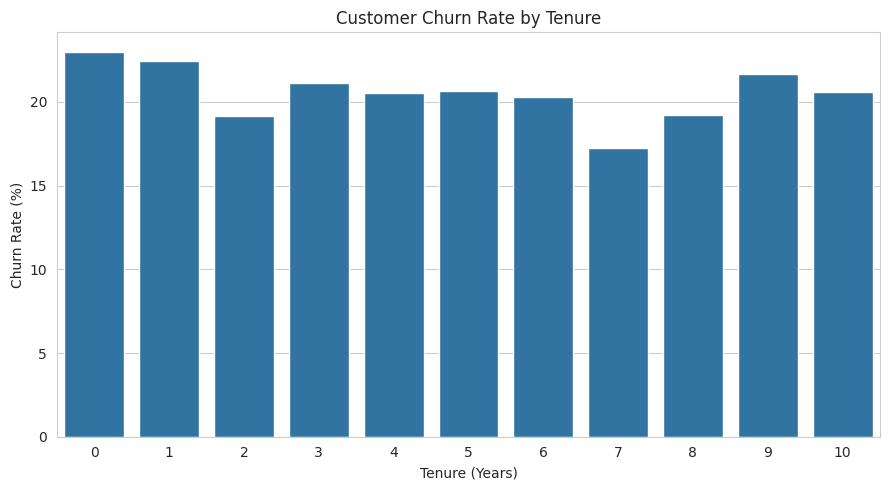


CHURN RATE BY BALANCE GROUP (%)


,Exited
BalanceGroup,
Zero Balance,13.82
0-50K,34.67
50-100K,19.88
100-150K,25.77
150-200K,21.93
200K+,55.88


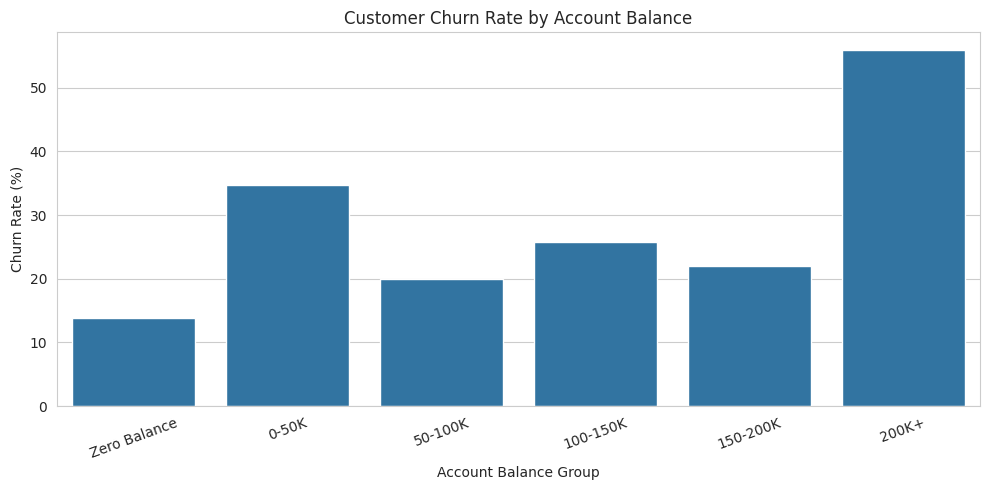


CHURN RATE BY NUMBER OF PRODUCTS (%)


,Exited
NumOfProducts,
1,27.71
2,7.58
3,82.71
4,100.00


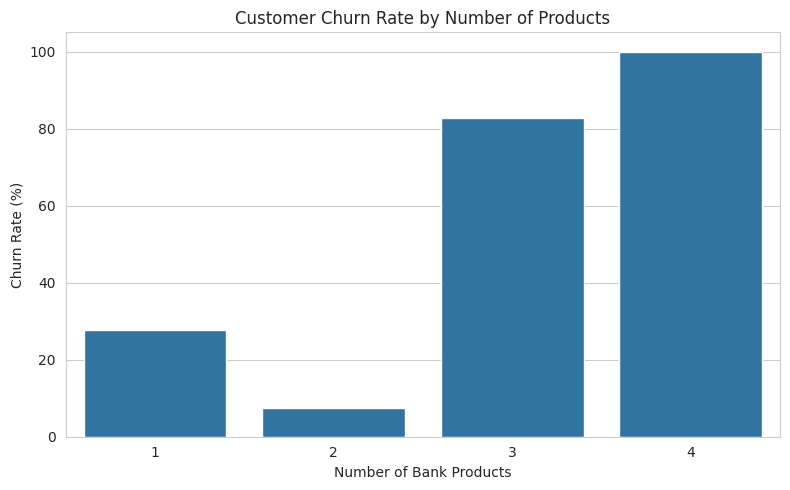

In [ ]:
# STEP 8 - CHURN BY TENURE, BALANCE AND PRODUCTS

# 1. CHURN BY TENURE
tenure_churn = df.groupby('Tenure')['Exited'].mean() * 100

print("CHURN RATE BY TENURE (%)")
display(tenure_churn.round(2))

plt.figure(figsize=(9, 5))
sns.barplot(x=tenure_churn.index, y=tenure_churn.values)

plt.title('Customer Churn Rate by Tenure')
plt.xlabel('Tenure (Years)')
plt.ylabel('Churn Rate (%)')
plt.tight_layout()
plt.show()

# 2. CHURN BY BALANCE
df['BalanceGroup'] = pd.cut(
    df['Balance'],
    bins=[-1, 0, 50000, 100000, 150000, 200000, float('inf')],
    labels=['Zero Balance', '0-50K', '50-100K', '100-150K', '150-200K', '200K+']
)

balance_churn = df.groupby('BalanceGroup', observed=False)['Exited'].mean() * 100

print("\nCHURN RATE BY BALANCE GROUP (%)")
display(balance_churn.round(2))

plt.figure(figsize=(10, 5))
sns.barplot(x=balance_churn.index, y=balance_churn.values)

plt.title('Customer Churn Rate by Account Balance')
plt.xlabel('Account Balance Group')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# 3. CHURN BY NUMBER OF PRODUCTS
product_churn = df.groupby('NumOfProducts')['Exited'].mean() * 100

print("\nCHURN RATE BY NUMBER OF PRODUCTS (%)")
display(product_churn.round(2))

plt.figure(figsize=(8, 5))
sns.barplot(x=product_churn.index, y=product_churn.values)

plt.title('Customer Churn Rate by Number of Products')
plt.xlabel('Number of Bank Products')
plt.ylabel('Churn Rate (%)')
plt.tight_layout()
plt.show()

CHURN RATE BY ACTIVE MEMBERSHIP (%)


,Exited
IsActiveMember,
0,26.85
1,14.27


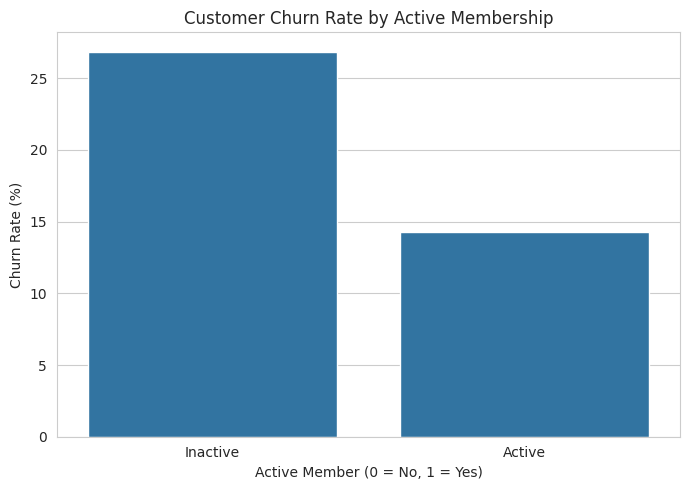


CHURN RATE BY CREDIT CARD OWNERSHIP (%)


,Exited
HasCrCard,
0,20.81
1,20.18


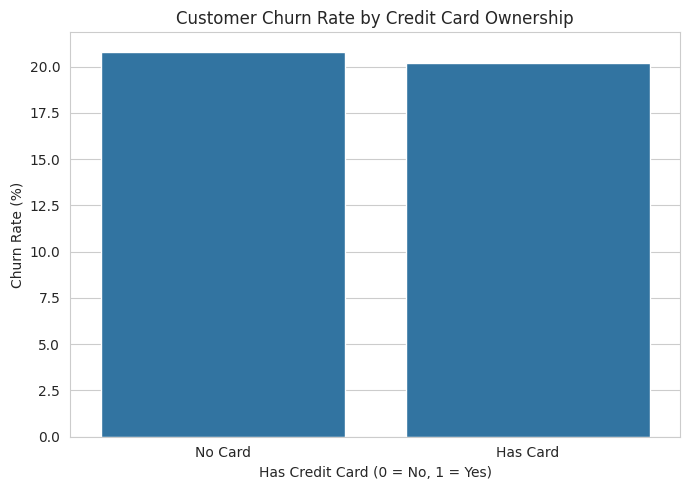

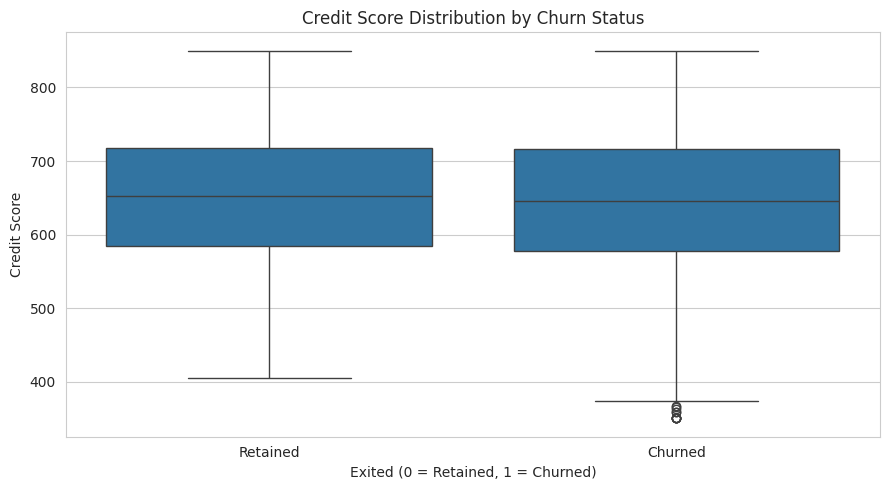


AVERAGE CREDIT SCORE BY CHURN STATUS


,CreditScore
Exited,
0,651.85
1,645.35



CHURN RATE BY SALARY GROUP (%)


,Exited
SalaryGroup,
Very Low,20.15
Low,19.82
Medium,20.06
High,20.21
Very High,21.61


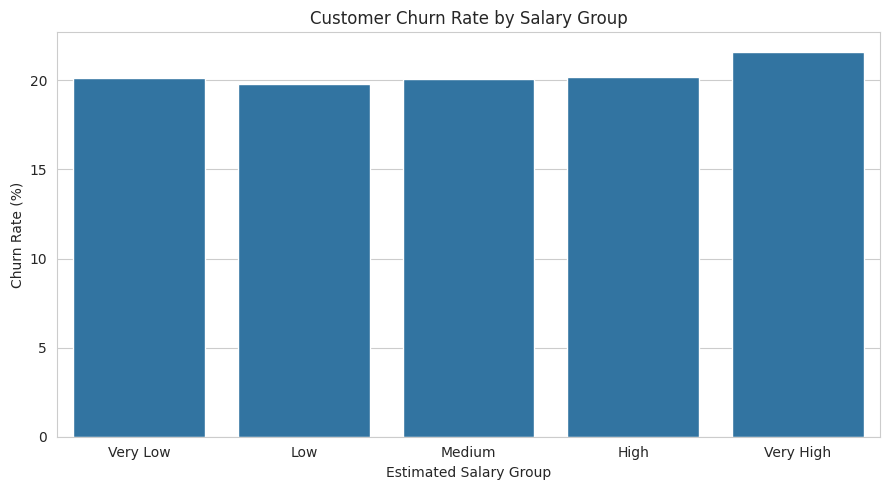

In [ ]:
# STEP 9 - CHURN BY ACTIVITY, CREDIT CARD, CREDIT SCORE & SALARY

# 1. CHURN BY ACTIVE MEMBERSHIP
activity_churn = df.groupby('IsActiveMember')['Exited'].mean() * 100

print("CHURN RATE BY ACTIVE MEMBERSHIP (%)")
display(activity_churn.round(2))

plt.figure(figsize=(7, 5))
sns.barplot(x=activity_churn.index, y=activity_churn.values)

plt.title('Customer Churn Rate by Active Membership')
plt.xlabel('Active Member (0 = No, 1 = Yes)')
plt.ylabel('Churn Rate (%)')
plt.xticks([0, 1], ['Inactive', 'Active'])
plt.tight_layout()
plt.show()

# 2. CHURN BY CREDIT CARD OWNERSHIP
card_churn = df.groupby('HasCrCard')['Exited'].mean() * 100

print("\nCHURN RATE BY CREDIT CARD OWNERSHIP (%)")
display(card_churn.round(2))

plt.figure(figsize=(7, 5))
sns.barplot(x=card_churn.index, y=card_churn.values)

plt.title('Customer Churn Rate by Credit Card Ownership')
plt.xlabel('Has Credit Card (0 = No, 1 = Yes)')
plt.ylabel('Churn Rate (%)')
plt.xticks([0, 1], ['No Card', 'Has Card'])
plt.tight_layout()
plt.show()

# 3. CHURN BY CREDIT SCORE
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x='Exited', y='CreditScore')

plt.title('Credit Score Distribution by Churn Status')
plt.xlabel('Exited (0 = Retained, 1 = Churned)')
plt.ylabel('Credit Score')
plt.xticks([0, 1], ['Retained', 'Churned'])
plt.tight_layout()
plt.show()

print("\nAVERAGE CREDIT SCORE BY CHURN STATUS")
display(df.groupby('Exited')['CreditScore'].mean().round(2))

# 4. CHURN BY ESTIMATED SALARY
df['SalaryGroup'] = pd.cut(
    df['EstimatedSalary'],
    bins=5,
    labels=['Very Low', 'Low', 'Medium', 'High', 'Very High']
)

salary_churn = df.groupby('SalaryGroup', observed=False)['Exited'].mean() * 100

print("\nCHURN RATE BY SALARY GROUP (%)")
display(salary_churn.round(2))

plt.figure(figsize=(9, 5))
sns.barplot(x=salary_churn.index, y=salary_churn.values)

plt.title('Customer Churn Rate by Salary Group')
plt.xlabel('Estimated Salary Group')
plt.ylabel('Churn Rate (%)')
plt.tight_layout()
plt.show()

In [ ]:
# STEP 10 - PREPARE CLEAN DATASET FOR MACHINE LEARNING

# Create a separate copy so the original dataset remains unchanged
df_clean = df.copy()

# Remove customer identifiers and temporary EDA categories
columns_to_drop = ['CustomerId', 'Surname', 'BalanceGroup', 'SalaryGroup']

df_clean.drop(columns=columns_to_drop, errors='ignore', inplace=True)

# Check whether Year is constant
if 'Year' in df_clean.columns and df_clean['Year'].nunique() == 1:
    df_clean.drop(columns=['Year'], inplace=True)
    print("Year column removed because it contains only one unique value.")

# Display cleaned dataset
print("Cleaned dataset created successfully!")
print("Cleaned dataset shape:", df_clean.shape)

print("\nRemaining columns:")
print(df_clean.columns.tolist())

print("\nFirst 5 rows of cleaned dataset:")
display(df_clean.head())

Year column removed because it contains only one unique value.
Cleaned dataset created successfully!
Cleaned dataset shape: (10000, 11)

Remaining columns:
['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']

First 5 rows of cleaned dataset:


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [ ]:
# STEP 11 - SAVE CLEANED DATASET

# Save the cleaned data as a CSV file
df_clean.to_csv('Bank_Churn_Cleaned.csv', index=False)

print("Cleaned dataset saved successfully!")
print("File name: Bank_Churn_Cleaned.csv")

Cleaned dataset saved successfully!
File name: Bank_Churn_Cleaned.csv


In [ ]:
from google.colab import files

files.download('Bank_Churn_Cleaned.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
# STEP 1: IMPORT LIBRARIES

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [22]:
# STEP 2: LOAD CLEANED DATASET

import glob
import os

csv_files = glob.glob('/content/*Cleaned*.csv')

print("Files found:", csv_files)

file_path = csv_files[0]
df_model = pd.read_csv(file_path)

print("\nDataset loaded successfully!")
print("File name:", os.path.basename(file_path))
print("Dataset shape:", df_model.shape)

display(df_model.head())

Files found: ['/content/Bank_Churn_Cleaned.csv']

Dataset loaded successfully!
File name: Bank_Churn_Cleaned.csv
Dataset shape: (10000, 11)


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [23]:
# STEP 3: SEPARATE FEATURES AND TARGET

# Target variable
y = df_model['Exited']

# Input features
X = df_model.drop('Exited', axis=1)

print("Features and target separated successfully!")
print("\nNumber of input features:", X.shape[1])
print("Number of target values:", y.shape[0])

print("\nInput feature columns:")
print(X.columns.tolist())

print("\nTarget distribution:")
display(y.value_counts())

Features and target separated successfully!

Number of input features: 10
Number of target values: 10000

Input feature columns:
['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']

Target distribution:


,count
Exited,
0,7963
1,2037


In [24]:
# STEP 4: FEATURE ENGINEERING

# 1. Balance-to-Salary Ratio
X['BalanceSalaryRatio'] = X['Balance'] / (X['EstimatedSalary'] + 1)

# 2. Product Density
X['ProductDensity'] = X['NumOfProducts'] / (X['Tenure'] + 1)

# 3. Engagement-Product Interaction
X['EngagementProduct'] = X['IsActiveMember'] * X['NumOfProducts']

# 4. Age-Tenure Interaction
X['AgeTenureInteraction'] = X['Age'] * X['Tenure']

print("Feature engineering completed successfully!")

print("\nNew features added:")
print([
    'BalanceSalaryRatio',
    'ProductDensity',
    'EngagementProduct',
    'AgeTenureInteraction'
])

print("\nUpdated dataset shape:", X.shape)

display(X.head())

Feature engineering completed successfully!

New features added:
['BalanceSalaryRatio', 'ProductDensity', 'EngagementProduct', 'AgeTenureInteraction']

Updated dataset shape: (10000, 14)


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,BalanceSalaryRatio,ProductDensity,EngagementProduct,AgeTenureInteraction
0,619,France,Female,42,2,0.00,1,1,1,101348.88,0.000000,0.333333,1,84
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0.744670,0.500000,1,41
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1.401362,0.333333,0,336
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0.000000,1.000000,0,39
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,1.587035,0.333333,1,86


In [25]:
# STEP 5: IDENTIFY CATEGORICAL AND NUMERICAL FEATURES

categorical_features = X.select_dtypes(include=['object']).columns.tolist()
numerical_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

print("Categorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

print("\nTotal categorical features:", len(categorical_features))
print("Total numerical features:", len(numerical_features))

Categorical features:
['Geography', 'Gender']

Numerical features:
['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'BalanceSalaryRatio', 'ProductDensity', 'EngagementProduct', 'AgeTenureInteraction']

Total categorical features: 2
Total numerical features: 12


In [26]:
# STEP 6: PREPROCESSING PIPELINE

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")
print("\nNumerical features will be standardized.")
print("Categorical features will be one-hot encoded.")

Preprocessing pipeline created successfully!

Numerical features will be standardized.
Categorical features will be one-hot encoded.


In [27]:
# STEP 7: TRAIN-TEST SPLIT

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Data split completed successfully!")

print("\nTraining set size:", X_train.shape)
print("Testing set size:", X_test.shape)

print("\nChurn distribution in training set:")
display(y_train.value_counts(normalize=True).round(3))

print("\nChurn distribution in testing set:")
display(y_test.value_counts(normalize=True).round(3))

Data split completed successfully!

Training set size: (8000, 14)
Testing set size: (2000, 14)

Churn distribution in training set:


,proportion
Exited,
0,0.796
1,0.204



Churn distribution in testing set:


,proportion
Exited,
0,0.796
1,0.204


In [28]:
# STEP 8: CHECK CLASS IMBALANCE AND CALCULATE CLASS WEIGHTS

from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train)

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train
)

class_weight_dict = dict(zip(classes, class_weights))

print("Class weights calculated successfully!")
print("\nClass weight dictionary:")
print(class_weight_dict)

print("\nTraining class distribution:")
display(y_train.value_counts())

Class weights calculated successfully!

Class weight dictionary:
{np.int64(0): np.float64(0.6279434850863422), np.int64(1): np.float64(2.4539877300613497)}

Training class distribution:


,count
Exited,
0,6370
1,1630


In [29]:
# STEP 9: LOGISTIC REGRESSION MODEL

logistic_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        class_weight='balanced',
        max_iter=1000,
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [30]:
# STEP 10: DECISION TREE MODEL

decision_tree_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(
        class_weight='balanced',
        max_depth=8,
        min_samples_split=20,
        min_samples_leaf=10,
        random_state=42
    ))
])

decision_tree_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [31]:
# STEP 11: RANDOM FOREST MODEL

random_forest_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        min_samples_split=20,
        min_samples_leaf=5,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [32]:
# STEP 12: GRADIENT BOOSTING MODEL

gradient_boosting_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

gradient_boosting_model.fit(X_train, y_train)

print("Gradient Boosting model trained successfully!")

Gradient Boosting model trained successfully!


In [33]:
# STEP 13A: INSTALL XGBOOST

!pip install xgboost -q

print("XGBoost installation completed!")

XGBoost installation completed!


In [34]:
# STEP 13B: TRAIN XGBOOST MODEL

from xgboost import XGBClassifier

xgb_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', XGBClassifier(
        n_estimators=200,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric='logloss',
        random_state=42,
        n_jobs=-1
    ))
])

xgb_model.fit(X_train, y_train)

print("XGBoost model trained successfully!")

XGBoost model trained successfully!


In [35]:
# STEP 14: EVALUATE AND COMPARE ALL MODELS

models = {
    'Logistic Regression': logistic_model,
    'Decision Tree': decision_tree_model,
    'Random Forest': random_forest_model,
    'Gradient Boosting': gradient_boosting_model,
    'XGBoost': xgb_model
}

results = []

for name, model in models.items():

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1 Score': f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='ROC-AUC',
    ascending=False
).reset_index(drop=True)

print("MODEL PERFORMANCE COMPARISON")
display(results_df.round(4))

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Gradient Boosting,0.8675,0.7710,0.4963,0.6039,0.8659
1,Random Forest,0.8375,0.5876,0.6757,0.6286,0.8645
2,XGBoost,0.8695,0.7897,0.4889,0.6039,0.8637
3,Decision Tree,0.7665,0.4547,0.7396,0.5631,0.8229
4,Logistic Regression,0.7095,0.3827,0.6978,0.4943,0.7759


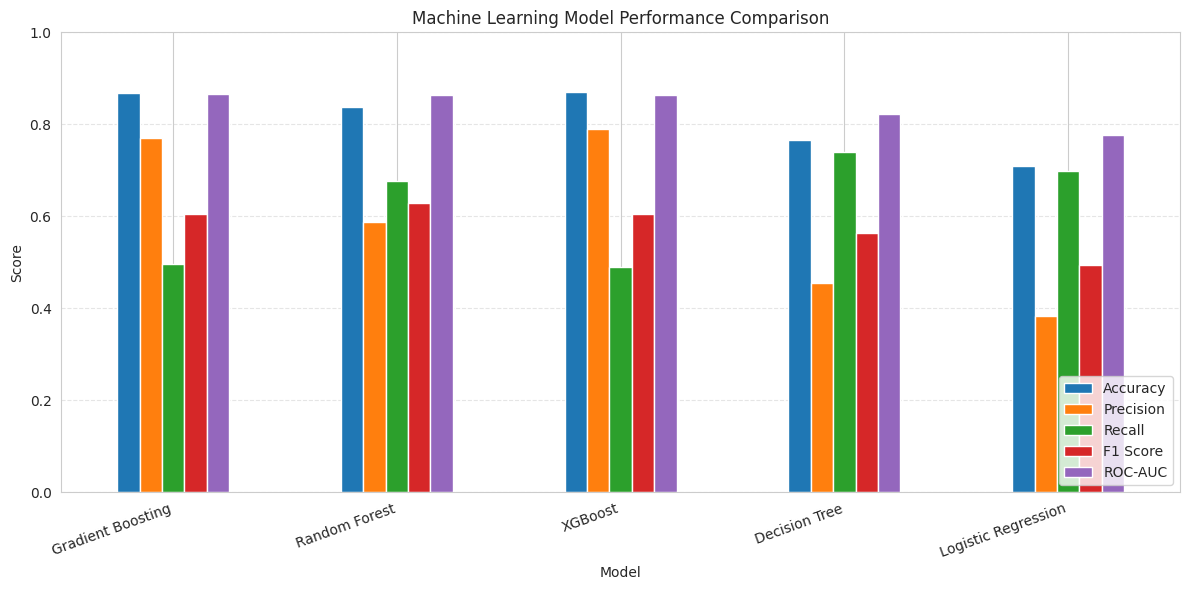

In [36]:
# STEP 15: VISUALIZE MODEL PERFORMANCE

metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC']

results_plot = results_df.set_index('Model')[metrics_to_plot]

results_plot.plot(kind='bar', figsize=(12, 6))

plt.title('Machine Learning Model Performance Comparison')
plt.ylabel('Score')
plt.xlabel('Model')
plt.ylim(0, 1)
plt.xticks(rotation=20, ha='right')
plt.legend(loc='lower right')
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [38]:
# STEP 16: SELECT THE BEST MODEL

best_model_name = results_df.loc[0, 'Model']

best_model = models[best_model_name]

print("BEST MODEL SELECTED")
print("-------------------------")
print("Model name:", best_model_name)
print("ROC-AUC:", round(results_df.loc[0, 'ROC-AUC'], 4))
print("Accuracy:", round(results_df.loc[0, 'Accuracy'], 4))
print("Precision:", round(results_df.loc[0, 'Precision'], 4))
print("Recall:", round(results_df.loc[0, 'Recall'], 4))
print("F1 Score:", round(results_df.loc[0, 'F1 Score'], 4))

BEST MODEL SELECTED
-------------------------
Model name: Gradient Boosting
ROC-AUC: 0.8659
Accuracy: 0.8675
Precision: 0.771
Recall: 0.4963
F1 Score: 0.6039


In [40]:
# STEP 17: CUSTOMER CHURN PROBABILITY & RISK SCORING

# Predict churn probabilities
churn_probabilities = best_model.predict_proba(X_test)[:, 1]

# Create risk scoring dataset
risk_scores = X_test.copy()

risk_scores['Actual_Exited'] = y_test.values
risk_scores['Churn_Probability'] = churn_probabilities
risk_scores['Churn_Risk_Score'] = (churn_probabilities * 100).round(2)

# Assign risk categories
risk_scores['Risk_Category'] = pd.cut(
    churn_probabilities,
    bins=[0, 0.30, 0.60, 0.80, 1.01],
    labels=['Low Risk', 'Medium Risk', 'High Risk', 'Critical Risk'],
    include_lowest=True
)

print("Customer risk scoring completed successfully!")

print("\nRisk category distribution:")
display(risk_scores['Risk_Category'].value_counts())

print("\nSample customer risk scores:")
display(risk_scores[['Age', 'Geography', 'Balance',
                     'Churn_Probability', 'Churn_Risk_Score',
                     'Risk_Category', 'Actual_Exited']].head(10))

Customer risk scoring completed successfully!

Risk category distribution:


,count
Risk_Category,
Low Risk,1573
Medium Risk,233
Critical Risk,106
High Risk,88



Sample customer risk scores:


,Age,Geography,Balance,Churn_Probability,Churn_Risk_Score,Risk_Category,Actual_Exited
5702,36,France,0.00,0.019170,1.92,Low Risk,0
3667,33,Germany,131023.76,0.093122,9.31,Low Risk,0
1617,40,Spain,0.00,0.036993,3.70,Low Risk,0
5673,34,Spain,139393.19,0.042230,4.22,Low Risk,0
4272,34,Spain,77826.80,0.107871,10.79,Low Risk,0
8270,34,Spain,0.00,0.165462,16.55,Low Risk,0
7079,30,Germany,130682.11,0.058707,5.87,Low Risk,0
5295,29,Germany,185544.36,0.280210,28.02,Low Risk,0
845,49,France,80001.23,0.507580,50.76,Medium Risk,0
5311,40,France,0.00,0.091910,9.19,Low Risk,0


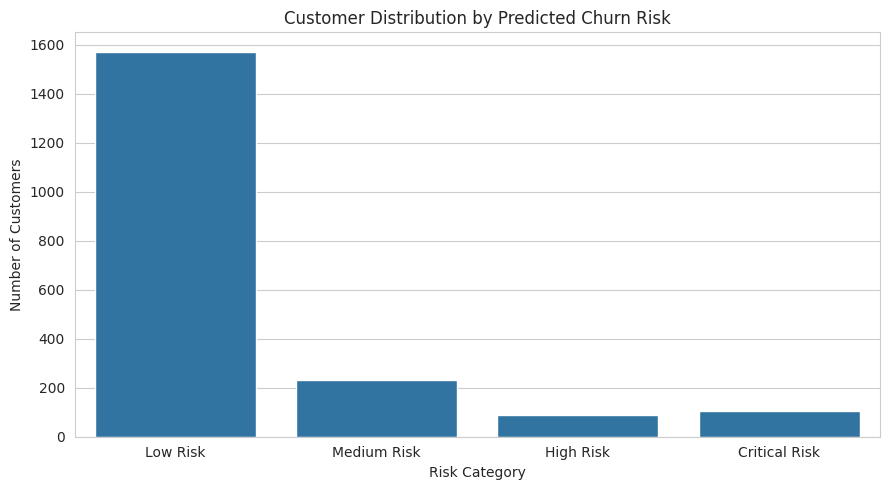

Customer distribution by risk category:


,count
Risk_Category,
Low Risk,1573
Medium Risk,233
High Risk,88
Critical Risk,106


In [41]:
# STEP 18: CUSTOMER RISK DISTRIBUTION

risk_order = ['Low Risk', 'Medium Risk', 'High Risk', 'Critical Risk']

risk_counts = risk_scores['Risk_Category'].value_counts().reindex(risk_order)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=risk_counts.index,
    y=risk_counts.values
)

plt.title('Customer Distribution by Predicted Churn Risk')
plt.xlabel('Risk Category')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()

print("Customer distribution by risk category:")
display(risk_counts)

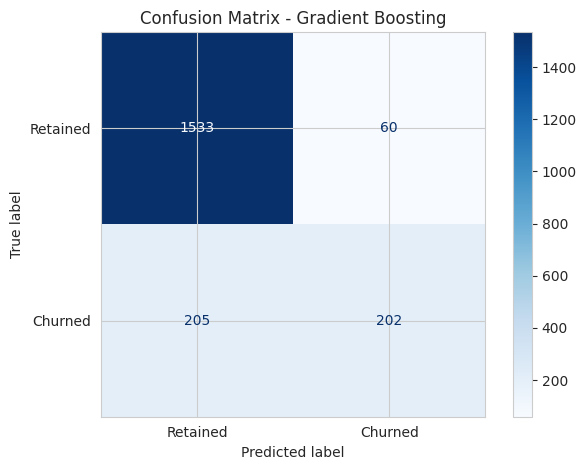

Confusion matrix values:
[[1533   60]
 [ 205  202]]


In [42]:
# STEP 19: CONFUSION MATRIX

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

best_predictions = best_model.predict(X_test)

cm = confusion_matrix(y_test, best_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Retained', 'Churned']
)

disp.plot(cmap='Blues', values_format='d')

plt.title(f'Confusion Matrix - {best_model_name}')
plt.tight_layout()
plt.show()

print("Confusion matrix values:")
print(cm)

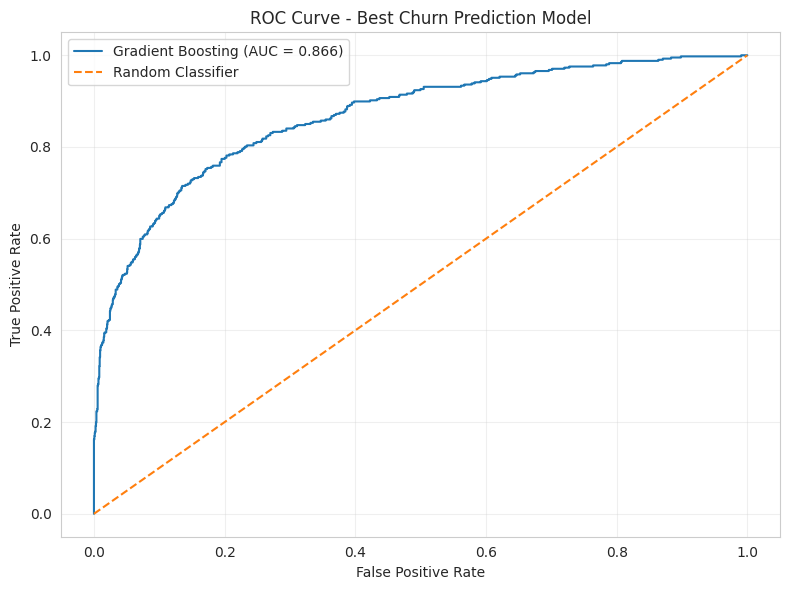

ROC-AUC: 0.8659


In [43]:
# STEP 20: ROC CURVE

from sklearn.metrics import roc_curve, auc

best_probabilities = best_model.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, best_probabilities)
roc_auc_value = auc(fpr, tpr)

plt.figure(figsize=(8, 6))

plt.plot(fpr, tpr, label=f'{best_model_name} (AUC = {roc_auc_value:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.title('ROC Curve - Best Churn Prediction Model')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("ROC-AUC:", round(roc_auc_value, 4))

TOP 15 IMPORTANT FEATURES


,Feature,Importance
1,num__Age,0.372351
4,num__NumOfProducts,0.277711
10,num__EngagementProduct,0.074793
3,num__Balance,0.067518
13,cat__Geography_Germany,0.053510
6,num__IsActiveMember,0.041193
8,num__BalanceSalaryRatio,0.028687
7,num__EstimatedSalary,0.026388
0,num__CreditScore,0.021103
11,num__AgeTenureInteraction,0.013216


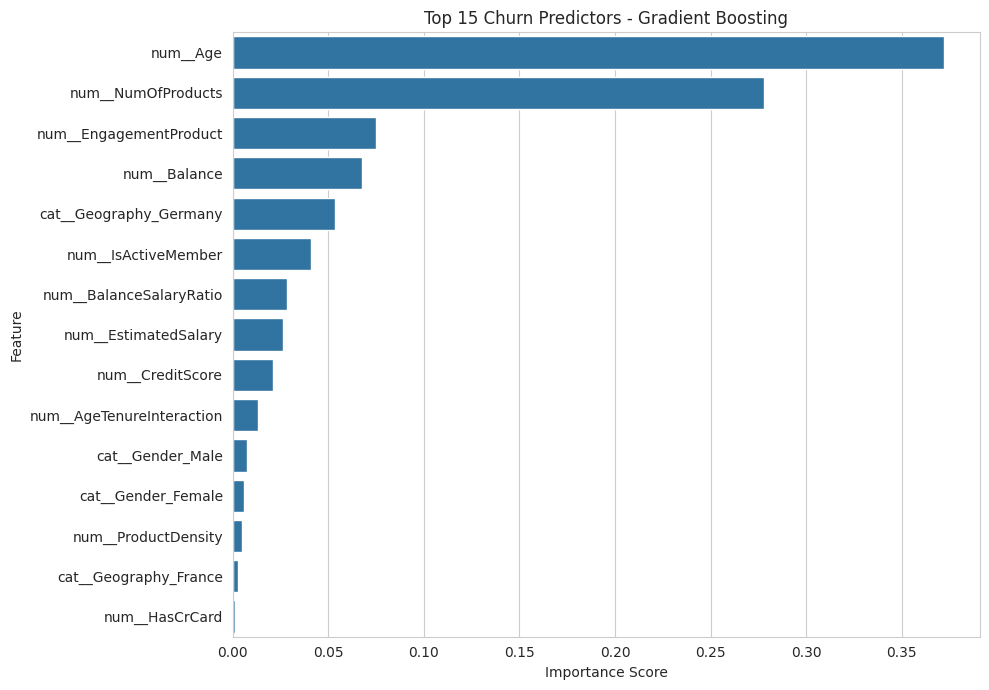

In [44]:
# STEP 21: FEATURE IMPORTANCE ANALYSIS

classifier = best_model.named_steps['classifier']
processed_features = best_model.named_steps['preprocessor'].get_feature_names_out()

if hasattr(classifier, 'feature_importances_'):
    importance_values = classifier.feature_importances_

elif hasattr(classifier, 'coef_'):
    importance_values = np.abs(classifier.coef_[0])

else:
    raise ValueError("Feature importance is not supported by this model.")

feature_importance_df = pd.DataFrame({
    'Feature': processed_features,
    'Importance': importance_values
}).sort_values(by='Importance', ascending=False)

print("TOP 15 IMPORTANT FEATURES")
display(feature_importance_df.head(15))

plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance_df.head(15),
    x='Importance',
    y='Feature'
)

plt.title(f'Top 15 Churn Predictors - {best_model_name}')
plt.xlabel('Importance Score')
plt.ylabel('Feature')

plt.tight_layout()
plt.show()

In [45]:
# STEP 22: HIGH-RISK CUSTOMER PRIORITY LIST

priority_customers = risk_scores.sort_values(
    by='Churn_Risk_Score',
    ascending=False
).copy()

priority_customers['Priority_Rank'] = range(
    1, len(priority_customers) + 1
)

print("TOP 20 HIGH-RISK CUSTOMERS")
display(
    priority_customers[
        ['Priority_Rank', 'Age', 'Geography', 'Gender',
         'Balance', 'NumOfProducts', 'IsActiveMember',
         'Churn_Risk_Score', 'Risk_Category', 'Actual_Exited']
    ].head(20)
)

TOP 20 HIGH-RISK CUSTOMERS


,Priority_Rank,Age,Geography,Gender,Balance,NumOfProducts,IsActiveMember,Churn_Risk_Score,Risk_Category,Actual_Exited
70,1,58,Germany,Male,133745.44,4,0,99.80,Critical Risk,1
5950,2,57,Germany,Female,112281.60,3,0,98.99,Critical Risk,1
3549,3,61,France,Female,62055.17,3,0,98.52,Critical Risk,1
2473,4,57,Germany,Female,163146.46,1,0,98.43,Critical Risk,1
2092,5,38,Spain,Male,250898.09,3,1,98.35,Critical Risk,1
5010,6,49,Germany,Male,121205.15,4,1,98.32,Critical Risk,1
6255,7,55,Germany,Male,111362.76,3,0,98.32,Critical Risk,1
555,8,51,Spain,Female,154962.99,3,1,98.29,Critical Risk,1
6831,9,52,Germany,Female,139493.25,3,0,97.86,Critical Risk,1
9215,10,37,Germany,Female,134171.80,4,1,97.79,Critical Risk,1


In [47]:
# STEP 23: SAVE DAY 2 OUTPUTS

import os

os.makedirs('Day2_Outputs', exist_ok=True)

# 1. Model comparison
results_df.to_csv('Day2_Outputs/Model_Comparison.csv', index=False)

# 2. Customer risk scores
risk_scores.to_csv('Day2_Outputs/Customer_Risk_Scores.csv', index=False)

# 3. High-risk customer priority list
priority_customers.to_csv(
    'Day2_Outputs/High_Risk_Customer_Priority_List.csv',
    index=False
)

# 4. Feature importance
feature_importance_df.to_csv(
    'Day2_Outputs/Feature_Importance.csv',
    index=False
)

print("Day 2 output files saved successfully!")
print("\nFiles created:")
print(os.listdir('Day2_Outputs'))

Day 2 output files saved successfully!

Files created:
['Model_Comparison.csv', 'Feature_Importance.csv', 'Customer_Risk_Scores.csv', 'High_Risk_Customer_Priority_List.csv']


In [48]:
# STEP 24: SAVE TRAINED MACHINE LEARNING MODELS

import joblib
import json
import os

os.makedirs('Day2_Outputs/Models', exist_ok=True)

# Save the best model
joblib.dump(
    best_model,
    'Day2_Outputs/Models/Best_Churn_Prediction_Model.pkl'
)

# Save all trained models
joblib.dump(
    models,
    'Day2_Outputs/Models/All_Churn_Models.pkl'
)

# Save best model information
model_info = {
    'Best_Model': best_model_name,
    'Selection_Metric': 'ROC-AUC',
    'ROC_AUC_Score': float(results_df.loc[0, 'ROC-AUC'])
}

with open('Day2_Outputs/Models/Best_Model_Info.json', 'w') as f:
    json.dump(model_info, f, indent=4)

print("All trained models saved successfully!")
print("\nSaved files:")
print(os.listdir('Day2_Outputs/Models'))

All trained models saved successfully!

Saved files:
['All_Churn_Models.pkl', 'Best_Model_Info.json', 'Best_Churn_Prediction_Model.pkl']


In [49]:
# STEP 25: ZIP AND DOWNLOAD DAY 2 OUTPUTS

import shutil
from google.colab import files

shutil.make_archive(
    'Bank_Churn_Day2_Outputs',
    'zip',
    'Day2_Outputs'
)

files.download('Bank_Churn_Day2_Outputs.zip')

print("Day 2 outputs ZIP file created successfully!")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Day 2 outputs ZIP file created successfully!
